In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/eslamfawzysayed/h-c-hybrid-model111/final_data_complete.xlsx


In [2]:
import pandas as pd 
import numpy as np 
import seaborn as sns 
import matplotlib.pyplot as plt
import plotly.express as px
import warnings
warnings.filterwarnings('ignore')

In [3]:
import pandas as pd
from pandas import DataFrame
import math
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn import tree
import graphviz
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from collections import Counter
from pprint import pprint

In [4]:
import pandas as pd

# header=1 means the second row (index 1) is the column names
data = pd.read_excel('/kaggle/input/datasets/eslamfawzysayed/h-c-hybrid-model111/final_data_complete.xlsx', header=0)

# Display column names
print("Column names (features):")
print(data.columns.tolist())

# Display first 5 rows
print("\nFirst 5 rows:")
print(data.head())

Column names (features):
['C%', 'H%', 'N%', 'S%', 'O%', 'Ash%', 'Volatile matter%', 'Fixed carbon%', 'HHV (MJ/Kg)', 'DM(%)', 'water Content (%)', 'Temprature(°C)', 'Reaction Time (min)', 'yield(%)', 'Cc (%)', 'Hc(%)', 'Nc(%)', 'Sc(%)', 'Oc(%)', 'HHVc (MJ/Kg)', 'EY(%)', 'ED(%)', 'CR(%)', 'HC- Volatile matter%', 'HC- Fixed carbon%', 'HC- Ash(%)']

First 5 rows:
      C%    H%    N%    S%     O%   Ash%  Volatile matter%  Fixed carbon%  \
0  34.78  3.93  5.04  1.15  20.32  31.77         58.537864       8.139291   
1  34.78  3.93  5.04  1.15  20.32  31.77         58.537864       8.139291   
2  34.78  3.93  5.04  1.15  20.32  31.77         58.537864       8.139291   
3  33.30  4.60  4.00  1.20  20.30  36.70         52.943581       9.546198   
4  33.30  4.60  4.00  1.20  20.30  36.70         52.943581       9.546198   

   HHV (MJ/Kg)  DM(%)  ...  Nc(%)  Sc(%)  Oc(%)  HHVc (MJ/Kg)      EY(%)  \
0        16.61    4.5  ...   5.11   1.07  15.46         16.97  70.291150   
1        16.61    4.5  

# Handle outliers by capping them to acceptable limits

Handling Outliers (Capping at IQR limits)

Data shape: (271, 26)

Numeric columns to process: 26

Outlier Capping Results

Outliers capped per column:
  - H%: 8 outliers capped
  - N%: 4 outliers capped
  - S%: 13 outliers capped
  - O%: 4 outliers capped
  - Volatile matter%: 6 outliers capped
  - Fixed carbon%: 10 outliers capped
  - HHV (MJ/Kg): 32 outliers capped
  - DM(%): 5 outliers capped
  - water Content (%): 8 outliers capped
  - Temprature(°C): 1 outliers capped
  - Reaction Time (min): 52 outliers capped
  - yield(%): 2 outliers capped
  - Nc(%): 10 outliers capped
  - Sc(%): 10 outliers capped
  - HHVc (MJ/Kg): 17 outliers capped
  - EY(%): 3 outliers capped
  - ED(%): 13 outliers capped
  - CR(%): 13 outliers capped
  - HC- Fixed carbon%: 8 outliers capped

Total outliers capped: 219

Statistical Summary (After Capping)

First numeric column stats after capping:
               C%          H%          N%          S%          O%        Ash%  \
count  271.000000  271.000000 

/kaggle/working/data_no_outliers.xlsx


Distribution plot saved to: outliers_capped_distribution.png


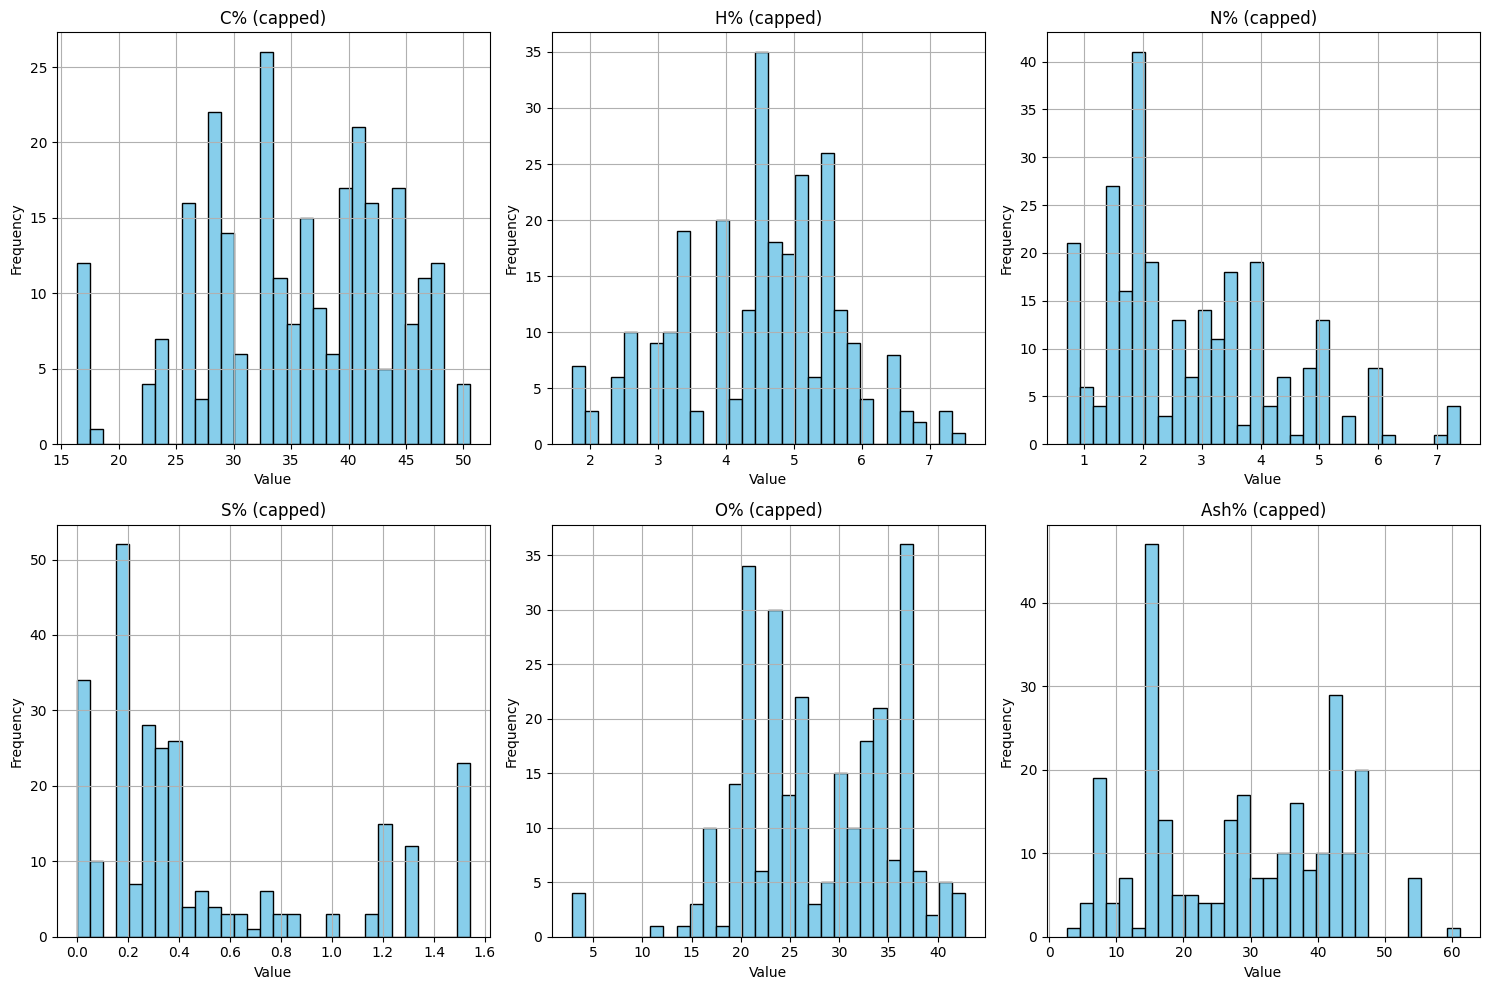


✅ Outlier handling completed successfully!


In [5]:
# ============================================
# Handle outliers by capping them to acceptable limits
# ============================================

import pandas as pd
import numpy as np

# Load data
try:
    data = data_converted.copy()
except:
    data = pd.read_excel('/kaggle/input/datasets/eslamfawzysayed/h-c-hybrid-model111/final_data_complete.xlsx')

print("="*60)
print("Handling Outliers (Capping at IQR limits)")
print("="*60)

print(f"\nData shape: {data.shape}")

# Select only numeric columns
numeric_cols = data.select_dtypes(include=[np.number]).columns.tolist()
print(f"\nNumeric columns to process: {len(numeric_cols)}")

# ============================================
# Function to cap outliers using IQR method
# ============================================
def cap_outliers_iqr(df, column):
    """
    Cap outliers using the IQR method.
    Values beyond (Q1 - 1.5*IQR) and (Q3 + 1.5*IQR) are capped.
    """
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    # Count outliers before capping
    outliers_before = ((df[column] < lower_bound) | (df[column] > upper_bound)).sum()
    
    # Cap the values
    df[column] = df[column].clip(lower=lower_bound, upper=upper_bound)
    
    return df, outliers_before

# ============================================
# Apply outlier capping to all numeric columns
# ============================================
total_outliers = 0
outlier_summary = []

for col in numeric_cols:
    data, outliers_count = cap_outliers_iqr(data, col)
    if outliers_count > 0:
        outlier_summary.append((col, outliers_count))
        total_outliers += outliers_count

# ============================================
# Display results
# ============================================
print("\n" + "="*60)
print("Outlier Capping Results")
print("="*60)

if outlier_summary:
    print("\nOutliers capped per column:")
    for col, count in outlier_summary:
        print(f"  - {col}: {count} outliers capped")
    print(f"\nTotal outliers capped: {total_outliers}")
else:
    print("\nNo outliers detected in any numeric column!")

# ============================================
# Statistical summary before and after
# ============================================
print("\n" + "="*60)
print("Statistical Summary (After Capping)")
print("="*60)

print("\nFirst numeric column stats after capping:")
print(data[numeric_cols].describe())

# ============================================
# Save data
# ============================================
data.to_excel('/kaggle/working/data_no_outliers.xlsx', index=False)
print("\nData saved to: data_no_outliers.xlsx")

from IPython.display import FileLink
display(FileLink('/kaggle/working/data_no_outliers.xlsx'))

# ============================================
# Show distribution plots (optional - requires matplotlib)
# ============================================
try:
    import matplotlib.pyplot as plt
    
    # Plot first 6 numeric columns
    n_cols = min(6, len(numeric_cols))
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    axes = axes.flatten()
    
    for i, col in enumerate(numeric_cols[:n_cols]):
        data[col].hist(bins=30, ax=axes[i], color='skyblue', edgecolor='black')
        axes[i].set_title(f'{col} (capped)')
        axes[i].set_xlabel('Value')
        axes[i].set_ylabel('Frequency')
    
    plt.tight_layout()
    plt.savefig('/kaggle/working/outliers_capped_distribution.png', dpi=150)
    print("\nDistribution plot saved to: outliers_capped_distribution.png")
    plt.show()
except:
    print("\nMatplotlib not available, skipping visualization")

print("\n" + "="*60)
print("✅ Outlier handling completed successfully!")
print("="*60)

In [6]:
print(f"Number of rows BEFORE capping: {len(data)}")
# ... capping code ...
print(f"Number of rows AFTER capping: {len(data)}")

Number of rows BEFORE capping: 271
Number of rows AFTER capping: 271


# Multi-Output Hybrid Model

# XGBOOST COMPARISON: STANDARD vs CHAIN REGRESSOR vs MULTI-OUTPUT REGRESSOR

In [7]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.multioutput import MultiOutputRegressor, RegressorChain
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, StackingRegressor, VotingRegressor
from sklearn.linear_model import Ridge, Lasso, ElasticNet, LinearRegression
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
import warnings
import time
import joblib

warnings.filterwarnings('ignore')

# ============================================
# 1. Load Data
# ============================================
print("="*80)
print("Loading Data")
print("="*80)

df = pd.read_excel('data_no_outliers.xlsx')

X = df.iloc[:, :13]
y = df.iloc[:, 13:26]

output_cols = df.columns[13:26].tolist()

print(f"Number of samples: {X.shape[0]}")
print(f"Number of inputs: {X.shape[1]}")
print(f"Number of outputs: {y.shape[1]}")
print(f"\nOutputs: {output_cols}")

# ============================================
# 2. Split Data
# ============================================
print("\n" + "="*80)
print("Splitting Data")
print("="*80)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Training size: {X_train.shape[0]}")
print(f"Testing size: {X_test.shape[0]}")

# ============================================
# 3. Define Strong Models Only (Without Decision Tree and SVR)
# ============================================
print("\n" + "="*80)
print("Defining Strong Models (XGBoost, LightGBM, CatBoost, RandomForest)")
print("="*80)

# ============================================
# 3.1 MultiOutputRegressor (Independent Models)
# ============================================
def create_multi_output(model):
    return MultiOutputRegressor(model, n_jobs=-1)

# ============================================
# 3.2 RegressorChain (Sequential Models)
# ============================================
def create_chain(model):
    return RegressorChain(model, order='random', random_state=42)

# ============================================
# Define Optimized Models
# ============================================

models_config = {
    # ========== XGBoost ==========
    'XGBoost_MultiOutput': {
        'model': create_multi_output(
            XGBRegressor(
                n_estimators=300,
                learning_rate=0.03,
                max_depth=6,
                subsample=0.85,
                colsample_bytree=0.85,
                min_child_weight=3,
                reg_alpha=0.1,
                reg_lambda=1.0,
                random_state=42,
                verbosity=0,
                n_jobs=-1
            )
        ),
        'type': 'MultiOutput',
        'scaled': False
    },
    'XGBoost_Chain': {
        'model': create_chain(
            XGBRegressor(
                n_estimators=300,
                learning_rate=0.03,
                max_depth=6,
                subsample=0.85,
                colsample_bytree=0.85,
                min_child_weight=3,
                reg_alpha=0.1,
                reg_lambda=1.0,
                random_state=42,
                verbosity=0,
                n_jobs=-1
            )
        ),
        'type': 'Chain',
        'scaled': False
    },
    
    # ========== LightGBM ==========
    'LightGBM_MultiOutput': {
        'model': create_multi_output(
            LGBMRegressor(
                n_estimators=300,
                learning_rate=0.03,
                num_leaves=25,
                max_depth=6,
                min_child_samples=20,
                subsample=0.85,
                colsample_bytree=0.85,
                reg_alpha=0.1,
                reg_lambda=1.0,
                random_state=42,
                verbose=-1,
                n_jobs=-1
            )
        ),
        'type': 'MultiOutput',
        'scaled': False
    },
    'LightGBM_Chain': {
        'model': create_chain(
            LGBMRegressor(
                n_estimators=300,
                learning_rate=0.03,
                num_leaves=25,
                max_depth=6,
                min_child_samples=20,
                subsample=0.85,
                colsample_bytree=0.85,
                reg_alpha=0.1,
                reg_lambda=1.0,
                random_state=42,
                verbose=-1,
                n_jobs=-1
            )
        ),
        'type': 'Chain',
        'scaled': False
    },
    
    # ========== CatBoost ==========
    'CatBoost_MultiOutput': {
        'model': create_multi_output(
            CatBoostRegressor(
                iterations=300,
                learning_rate=0.03,
                depth=6,
                l2_leaf_reg=3,
                border_count=128,
                random_seed=42,
                verbose=False,
                thread_count=-1
            )
        ),
        'type': 'MultiOutput',
        'scaled': False
    },
    'CatBoost_Chain': {
        'model': create_chain(
            CatBoostRegressor(
                iterations=300,
                learning_rate=0.03,
                depth=6,
                l2_leaf_reg=3,
                border_count=128,
                random_seed=42,
                verbose=False,
                thread_count=-1
            )
        ),
        'type': 'Chain',
        'scaled': False
    },
    
    # ========== RandomForest ==========
    'RandomForest_MultiOutput': {
        'model': create_multi_output(
            RandomForestRegressor(
                n_estimators=300,
                max_depth=12,
                min_samples_split=5,
                min_samples_leaf=2,
                max_features='sqrt',
                random_state=42,
                n_jobs=-1
            )
        ),
        'type': 'MultiOutput',
        'scaled': False
    },
    'RandomForest_Chain': {
        'model': create_chain(
            RandomForestRegressor(
                n_estimators=300,
                max_depth=12,
                min_samples_split=5,
                min_samples_leaf=2,
                max_features='sqrt',
                random_state=42,
                n_jobs=-1
            )
        ),
        'type': 'Chain',
        'scaled': False
    },
    
    # ========== ExtraTrees ==========
    'ExtraTrees_MultiOutput': {
        'model': create_multi_output(
            ExtraTreesRegressor(
                n_estimators=300,
                max_depth=12,
                min_samples_split=5,
                min_samples_leaf=2,
                max_features='sqrt',
                random_state=42,
                n_jobs=-1
            )
        ),
        'type': 'MultiOutput',
        'scaled': False
    },
    'ExtraTrees_Chain': {
        'model': create_chain(
            ExtraTreesRegressor(
                n_estimators=300,
                max_depth=12,
                min_samples_split=5,
                min_samples_leaf=2,
                max_features='sqrt',
                random_state=42,
                n_jobs=-1
            )
        ),
        'type': 'Chain',
        'scaled': False
    }
}

# ============================================
# 4. Train and Evaluate All Models
# ============================================
print("\n" + "="*80)
print("Training and Evaluating All Models")
print("="*80)

results = {}
trained_models = {}

for name, config in models_config.items():
    print(f"\n🔧 Training {name}...")
    start = time.time()
    
    model = config['model']
    X_train_use = X_train
    X_test_use = X_test
    
    try:
        # Train model
        model.fit(X_train_use, y_train)
        
        # Predict
        y_pred_train = model.predict(X_train_use)
        y_pred_test = model.predict(X_test_use)
        
        # Calculate metrics for each output
        train_r2_list = []
        test_r2_list = []
        train_rmse_list = []
        test_rmse_list = []
        train_mae_list = []
        test_mae_list = []
        
        for i in range(y_test.shape[1]):
            # Train
            train_r2 = r2_score(y_train.iloc[:, i], y_pred_train[:, i])
            train_rmse = np.sqrt(mean_squared_error(y_train.iloc[:, i], y_pred_train[:, i]))
            train_mae = mean_absolute_error(y_train.iloc[:, i], y_pred_train[:, i])
            
            # Test
            test_r2 = r2_score(y_test.iloc[:, i], y_pred_test[:, i])
            test_rmse = np.sqrt(mean_squared_error(y_test.iloc[:, i], y_pred_test[:, i]))
            test_mae = mean_absolute_error(y_test.iloc[:, i], y_pred_test[:, i])
            
            train_r2_list.append(train_r2)
            test_r2_list.append(test_r2)
            train_rmse_list.append(train_rmse)
            test_rmse_list.append(test_rmse)
            train_mae_list.append(train_mae)
            test_mae_list.append(test_mae)
        
        avg_train_r2 = np.mean(train_r2_list)
        avg_test_r2 = np.mean(test_r2_list)
        avg_train_rmse = np.mean(train_rmse_list)
        avg_test_rmse = np.mean(test_rmse_list)
        avg_train_mae = np.mean(train_mae_list)
        avg_test_mae = np.mean(test_mae_list)
        
        elapsed = time.time() - start
        
        results[name] = {
            'model': model,
            'type': config['type'],
            'time': elapsed,
            'avg_train_r2': avg_train_r2,
            'avg_test_r2': avg_test_r2,
            'avg_train_rmse': avg_train_rmse,
            'avg_test_rmse': avg_test_rmse,
            'avg_train_mae': avg_train_mae,
            'avg_test_mae': avg_test_mae,
            'train_r2_list': train_r2_list,
            'test_r2_list': test_r2_list,
            'train_rmse_list': train_rmse_list,
            'test_rmse_list': test_rmse_list,
            'train_mae_list': train_mae_list,
            'test_mae_list': test_mae_list
        }
        
        trained_models[name] = model
        
        print(f"   ✅ Time: {elapsed:.2f} seconds")
        print(f"   ✅ Train R²: {avg_train_r2:.4f} | Test R²: {avg_test_r2:.4f}")
        print(f"   ✅ Train RMSE: {avg_train_rmse:.4f} | Test RMSE: {avg_test_rmse:.4f}")
        
    except Exception as e:
        print(f"   ❌ Failed: {str(e)[:100]}")
        results[name] = None

# ============================================
# 5. Display Results of All Models
# ============================================
print("\n" + "="*80)
print("📊 Results of All Models (Sorted by Test R²)")
print("="*80)

# Filter out failed results
valid_results = {k: v for k, v in results.items() if v is not None}

# Sort results
sorted_results = sorted(
    valid_results.items(),
    key=lambda x: x[1]['avg_test_r2'],
    reverse=True
)

print(f"\n{'Model':<35} {'Test R²':<12} {'Train R²':<12} {'Time':<10}")
print("-"*80)
for i, (name, res) in enumerate(sorted_results, 1):
    print(f"{i}. {name:<32} {res['avg_test_r2']:.4f}     {res['avg_train_r2']:.4f}     {res['time']:.2f}s")

# ============================================
# 6. Select Best Model for Each Output
# ============================================
print("\n" + "="*80)
print("🎯 Selecting Best Model for Each Output")
print("="*80)

# Matrix to store best model for each output
best_models_per_target = {}
best_r2_per_target = []

for target_idx in range(y_test.shape[1]):
    target_name = output_cols[target_idx]
    best_model_name = None
    best_test_r2 = -np.inf
    best_model = None
    
    for name, res in valid_results.items():
        test_r2 = res['test_r2_list'][target_idx]
        if test_r2 > best_test_r2:
            best_test_r2 = test_r2
            best_model_name = name
            best_model = res['model']
    
    best_models_per_target[target_name] = {
        'model_name': best_model_name,
        'test_r2': best_test_r2,
        'model': best_model
    }
    best_r2_per_target.append(best_test_r2)
    
    print(f"{target_name:<25} → {best_model_name:<35} (R² = {best_test_r2:.4f})")

# ============================================
# 7. Build Final Hybrid Model
# ============================================
print("\n" + "="*80)
print("🔧 Building Final Hybrid Model")
print("="*80)

class HybridMultiOutputModel:
    """Hybrid model that selects the best model for each output"""
    
    def __init__(self, best_models_per_target):
        self.best_models_per_target = best_models_per_target
        self.target_names = list(best_models_per_target.keys())
        
    def predict(self, X):
        """Predict using the best model for each output"""
        n_samples = X.shape[0]
        n_targets = len(self.target_names)
        predictions = np.zeros((n_samples, n_targets))
        
        for i, target_name in enumerate(self.target_names):
            model_info = self.best_models_per_target[target_name]
            model = model_info['model']
            
            # Predict for this output
            pred = model.predict(X)
            
            # If model is of type MultiOutput or Chain, take the appropriate column
            if pred.ndim == 2:
                predictions[:, i] = pred[:, i]
            else:
                predictions[:, i] = pred
        
        return predictions
    
    def score(self, X, y):
        """Calculate R² for the hybrid model"""
        y_pred = self.predict(X)
        r2_list = []
        for i in range(y.shape[1]):
            r2 = r2_score(y.iloc[:, i], y_pred[:, i])
            r2_list.append(r2)
        return np.mean(r2_list)

# Create hybrid model
hybrid_model = HybridMultiOutputModel(best_models_per_target)

# ============================================
# 8. Evaluate Final Hybrid Model
# ============================================
print("\n" + "="*80)
print("📊 Evaluating Final Hybrid Model")
print("="*80)

# Predict
y_pred_train_hybrid = hybrid_model.predict(X_train)
y_pred_test_hybrid = hybrid_model.predict(X_test)

# Calculate metrics
hybrid_train_r2 = []
hybrid_test_r2 = []
hybrid_train_rmse = []
hybrid_test_rmse = []
hybrid_train_mae = []
hybrid_test_mae = []

for i in range(y_test.shape[1]):
    # Train
    train_r2 = r2_score(y_train.iloc[:, i], y_pred_train_hybrid[:, i])
    train_rmse = np.sqrt(mean_squared_error(y_train.iloc[:, i], y_pred_train_hybrid[:, i]))
    train_mae = mean_absolute_error(y_train.iloc[:, i], y_pred_train_hybrid[:, i])
    
    # Test
    test_r2 = r2_score(y_test.iloc[:, i], y_pred_test_hybrid[:, i])
    test_rmse = np.sqrt(mean_squared_error(y_test.iloc[:, i], y_pred_test_hybrid[:, i]))
    test_mae = mean_absolute_error(y_test.iloc[:, i], y_pred_test_hybrid[:, i])
    
    hybrid_train_r2.append(train_r2)
    hybrid_test_r2.append(test_r2)
    hybrid_train_rmse.append(train_rmse)
    hybrid_test_rmse.append(test_rmse)
    hybrid_train_mae.append(train_mae)
    hybrid_test_mae.append(test_mae)

avg_hybrid_train_r2 = np.mean(hybrid_train_r2)
avg_hybrid_test_r2 = np.mean(hybrid_test_r2)
avg_hybrid_train_rmse = np.mean(hybrid_train_rmse)
avg_hybrid_test_rmse = np.mean(hybrid_test_rmse)
avg_hybrid_train_mae = np.mean(hybrid_train_mae)
avg_hybrid_test_mae = np.mean(hybrid_test_mae)

print(f"\n🏆 Final Hybrid Model:")
print(f"   ✅ Train R²: {avg_hybrid_train_r2:.4f}")
print(f"   ✅ Test R²:  {avg_hybrid_test_r2:.4f}")
print(f"   ✅ Train RMSE: {avg_hybrid_train_rmse:.4f}")
print(f"   ✅ Test RMSE:  {avg_hybrid_test_rmse:.4f}")
print(f"   ✅ Train MAE: {avg_hybrid_train_mae:.4f}")
print(f"   ✅ Test MAE:  {avg_hybrid_test_mae:.4f}")

# ============================================
# 9. Display Detailed Results for Each Output
# ============================================
print("\n" + "="*80)
print("📊 Detailed Results for Each Output - Hybrid Model")
print("="*80)

print(f"\n{'Output':<25} {'Train R²':<12} {'Test R²':<12} {'Train RMSE':<12} {'Test RMSE':<12} {'Best Model':<35}")
print("-"*130)

for i, col in enumerate(output_cols):
    best_model = best_models_per_target[col]['model_name']
    print(f"{col:<25} {hybrid_train_r2[i]:.4f}     {hybrid_test_r2[i]:.4f}     {hybrid_train_rmse[i]:.4f}     {hybrid_test_rmse[i]:.4f}     {best_model:<35}")

# ============================================
# 10. Comparison with Best Individual Model
# ============================================
print("\n" + "="*80)
print("📊 Comparison of Hybrid Model with Best Individual Model")
print("="*80)

best_individual_name = sorted_results[0][0]
best_individual_res = sorted_results[0][1]

print(f"\nBest Individual Model: {best_individual_name}")
print(f"   Test R²: {best_individual_res['avg_test_r2']:.4f}")

print(f"\nFinal Hybrid Model:")
print(f"   Test R²: {avg_hybrid_test_r2:.4f}")

improvement = (avg_hybrid_test_r2 - best_individual_res['avg_test_r2']) * 100
print(f"\n📈 Improvement: {improvement:+.2f}%")

# ============================================
# 11. Build Additional Stacking Model (For Comparison)
# ============================================
print("\n" + "="*80)
print("🔧 Building Additional Stacking Model for Comparison")
print("="*80)

# Base estimators for Stacking
base_estimators = [
    ('xgb', XGBRegressor(
        n_estimators=200,
        learning_rate=0.03,
        max_depth=5,
        random_state=42,
        verbosity=0
    )),
    ('lgbm', LGBMRegressor(
        n_estimators=200,
        learning_rate=0.03,
        num_leaves=20,
        random_state=42,
        verbose=-1
    )),
    ('catboost', CatBoostRegressor(
        iterations=200,
        learning_rate=0.03,
        depth=5,
        random_seed=42,
        verbose=False
    )),
    ('rf', RandomForestRegressor(
        n_estimators=200,
        max_depth=8,
        random_state=42,
        n_jobs=-1
    ))
]

# Train Stacking for each output
print("\n🔄 Training Stacking (XGB + LGBM + CatBoost + RF)...")
start = time.time()

stacking_models = []
for target_idx in range(y_train.shape[1]):
    stacking_model = StackingRegressor(
        estimators=base_estimators,
        final_estimator=Ridge(alpha=0.5),
        cv=3,
        n_jobs=-1,
        verbose=0
    )
    stacking_model.fit(X_train, y_train.iloc[:, target_idx])
    stacking_models.append(stacking_model)

y_pred_stacking = np.column_stack([model.predict(X_test) for model in stacking_models])

stacking_r2 = []
for i in range(y_test.shape[1]):
    r2 = r2_score(y_test.iloc[:, i], y_pred_stacking[:, i])
    stacking_r2.append(r2)

avg_stacking = np.mean(stacking_r2)
elapsed = time.time() - start

print(f"   ✅ Time: {elapsed:.2f} seconds")
print(f"   ✅ Test R²: {avg_stacking:.4f}")

# ============================================
# 12. Comparison of Hybrid vs Stacking
# ============================================
print("\n" + "="*80)
print("📊 Comparison of Hybrid Model vs Stacking")
print("="*80)

print(f"\n{'Model':<35} {'Test R²':<12}")
print("-"*60)
print(f"Hybrid (Best per target): {avg_hybrid_test_r2:.4f}")
print(f"Stacking (4 models):      {avg_stacking:.4f}")

stacking_improvement = (avg_hybrid_test_r2 - avg_stacking) * 100
print(f"\n📈 Hybrid improvement over Stacking: {stacking_improvement:+.2f}%")

# ============================================
# 13. Save Results
# ============================================
print("\n" + "="*80)
print("Saving Results")
print("="*80)

# Save all models comparison
all_results_df = pd.DataFrame([
    {
        'Model': name,
        'Type': res['type'],
        'Time_s': res['time'],
        'Train_R2': res['avg_train_r2'],
        'Test_R2': res['avg_test_r2'],
        'Train_RMSE': res['avg_train_rmse'],
        'Test_RMSE': res['avg_test_rmse'],
        'Train_MAE': res['avg_train_mae'],
        'Test_MAE': res['avg_test_mae']
    }
    for name, res in valid_results.items()
])
all_results_df = all_results_df.sort_values('Test_R2', ascending=False)
all_results_df.to_excel('all_models_comparison_no_dt_svr.xlsx', index=False)
print("✅ Saved all models comparison to: all_models_comparison_no_dt_svr.xlsx")

# Save hybrid model details
hybrid_details_df = pd.DataFrame({
    'Output': output_cols,
    'Best_Model': [best_models_per_target[col]['model_name'] for col in output_cols],
    'Train_R2': hybrid_train_r2,
    'Test_R2': hybrid_test_r2,
    'Train_RMSE': hybrid_train_rmse,
    'Test_RMSE': hybrid_test_rmse,
    'Train_MAE': hybrid_train_mae,
    'Test_MAE': hybrid_test_mae
})
hybrid_details_df.to_excel('hybrid_model_details_no_dt_svr.xlsx', index=False)
print("✅ Saved hybrid model details to: hybrid_model_details_no_dt_svr.xlsx")

# Save Hybrid vs Stacking comparison
comparison_df = pd.DataFrame({
    'Model': ['Hybrid (Best per target)', 'Stacking (4 models)'],
    'Test_R2': [avg_hybrid_test_r2, avg_stacking]
})
comparison_df.to_excel('hybrid_vs_stacking_comparison.xlsx', index=False)
print("✅ Saved Hybrid vs Stacking comparison to: hybrid_vs_stacking_comparison.xlsx")

# Save hybrid model
joblib.dump(hybrid_model, 'hybrid_model_final_no_dt_svr.pkl')
print("✅ Saved hybrid model to: hybrid_model_final_no_dt_svr.pkl")

# ============================================
# 14. Final Summary
# ============================================
print("\n" + "="*80)
print("🎉 Final Summary")
print("="*80)

print(f"""
✅ Best Hybrid Model: Hybrid MultiOutput Model (Best per target)
✅ Test R²: {avg_hybrid_test_r2:.4f}
✅ Train R²: {avg_hybrid_train_r2:.4f}
✅ Improvement over best individual model: {improvement:+.2f}%
✅ Hybrid improvement over Stacking: {stacking_improvement:+.2f}%

📊 Outputs and their best models:
""")

for i, col in enumerate(output_cols):
    best_model = best_models_per_target[col]['model_name']
    print(f"   {col:<25} → {best_model:<35} (R² = {best_models_per_target[col]['test_r2']:.4f})")

print(f"""
📁 Saved files:
   • all_models_comparison_no_dt_svr.xlsx - All models comparison
   • hybrid_model_details_no_dt_svr.xlsx - Hybrid model details
   • hybrid_vs_stacking_comparison.xlsx - Hybrid vs Stacking comparison
   • hybrid_model_final_no_dt_svr.pkl - Final hybrid model

🔧 Models used:
   • XGBoost (MultiOutput + Chain)
   • LightGBM (MultiOutput + Chain)
   • CatBoost (MultiOutput + Chain)
   • RandomForest (MultiOutput + Chain)
   • ExtraTrees (MultiOutput + Chain)
   • Stacking (For comparison only)
""")

print("="*80)
print("✅ Completed successfully! 🚀")

Loading Data
Number of samples: 271
Number of inputs: 13
Number of outputs: 13

Outputs: ['yield(%)', 'Cc (%)', 'Hc(%)', 'Nc(%)', 'Sc(%)', 'Oc(%)', 'HHVc (MJ/Kg)', 'EY(%)', 'ED(%)', 'CR(%)', 'HC- Volatile matter%', 'HC- Fixed carbon%', 'HC- Ash(%)']

Splitting Data
Training size: 216
Testing size: 55

Defining Strong Models (XGBoost, LightGBM, CatBoost, RandomForest)

Training and Evaluating All Models

🔧 Training XGBoost_MultiOutput...
   ✅ Time: 3.87 seconds
   ✅ Train R²: 0.9868 | Test R²: 0.8574
   ✅ Train RMSE: 0.8740 | Test RMSE: 3.4376

🔧 Training XGBoost_Chain...
   ✅ Time: 7.24 seconds
   ✅ Train R²: 0.9734 | Test R²: 0.8568
   ✅ Train RMSE: 1.2635 | Test RMSE: 3.4405

🔧 Training LightGBM_MultiOutput...
   ✅ Time: 175.38 seconds
   ✅ Train R²: 0.9422 | Test R²: 0.8502
   ✅ Train RMSE: 1.9115 | Test RMSE: 3.4702

🔧 Training LightGBM_Chain...
   ✅ Time: 3.95 seconds
   ✅ Train R²: 0.9292 | Test R²: 0.8330
   ✅ Train RMSE: 2.1190 | Test RMSE: 3.5927

🔧 Training CatBoost_MultiOutp

# Actual vs. Predicted Values for Hydrochar Properties Using the Hybrid Ensemble Model


GENERATING PUBLICATION-QUALITY PLOTS - HYBRID MODEL (600 DPI)

Loading data...
Data loaded: 271 samples, 13 inputs, 13 outputs

Loading existing hybrid model...
Hybrid model loaded

Recreating train-test split...
Training samples: 216
Testing samples: 55

Predicting with hybrid model...
Predictions completed

Mapping best model per target from original results...
Best models loaded and corrected based on original results

GENERATING PUBLICATION-QUALITY PLOTS (600 DPI)

Generating plots for each output...
   yield(%): R2_Test = 0.7756 | Best Model = XGBoost_Chain
   Cc (%): R2_Test = 0.9709 | Best Model = XGBoost_MultiOutput
   Hc(%): R2_Test = 0.9290 | Best Model = XGBoost_MultiOutput
   Nc(%): R2_Test = 0.8394 | Best Model = CatBoost_MultiOutput
   Sc(%): R2_Test = 0.9212 | Best Model = XGBoost_Chain
   Oc(%): R2_Test = 0.8823 | Best Model = CatBoost_MultiOutput
   HHVc (MJ/Kg): R2_Test = 0.9705 | Best Model = XGBoost_MultiOutput
   EY(%): R2_Test = 0.6863 | Best Model = XGBoost_Chai

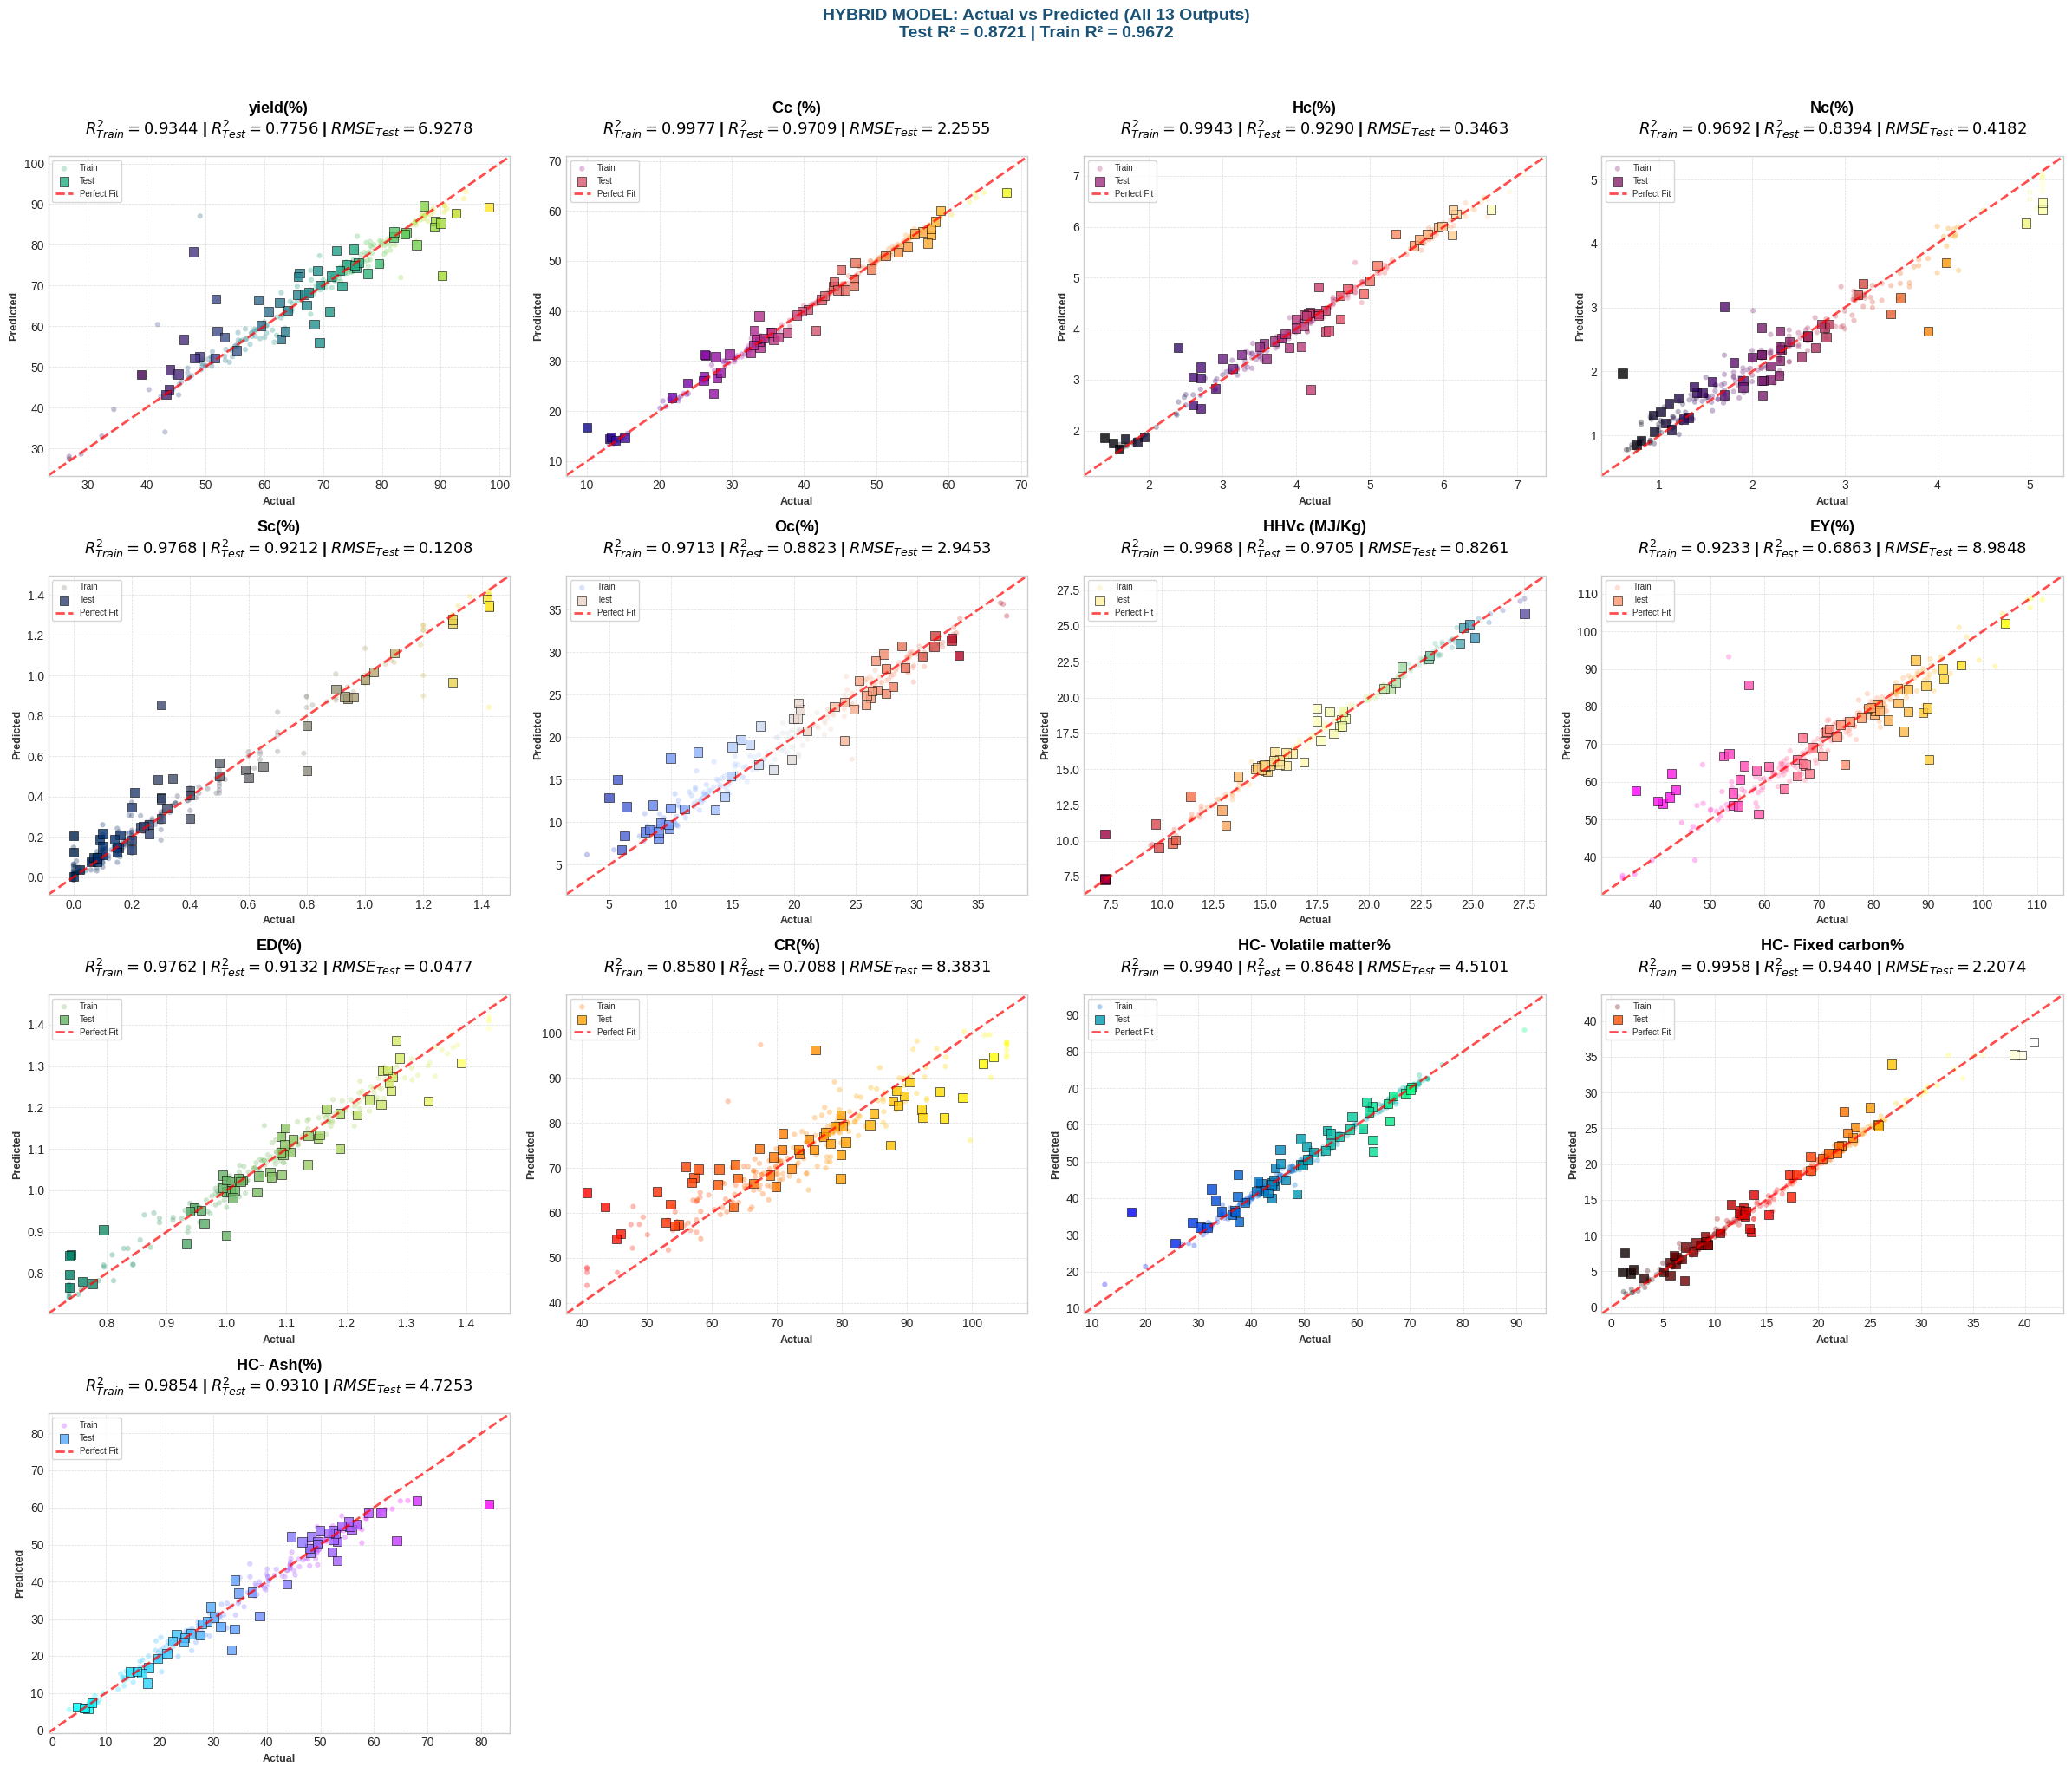


Saving detailed results
Results saved to: hybrid_model_plot_results.xlsx

Click below to download the high-resolution image:


/kaggle/working/hybrid_model_publication_plot_600dpi.png


FINAL SUMMARY
Hybrid Model Performance:
   - Test R2: 0.8721
   - Train R2: 0.9672
   - Test RMSE: 3.2845
   - Test MAE: 2.2752

Best Model Distribution:
   - XGBoost: 9/13 targets (69.2%)
   - CatBoost: 2/13 targets (15.4%)
   - LightGBM: 2/13 targets (15.4%)

Files Generated:
   - hybrid_model_publication_plot_600dpi.png (600 DPI)
   - hybrid_model_plot_results.xlsx
PUBLICATION-READY HYBRID MODEL PLOTS GENERATED!


In [10]:
# ============================================
# PLOTTING: HYBRID MODEL - Actual vs Predicted for All Outputs
# PUBLICATION QUALITY (600 DPI)
# ============================================

print("\n" + "="*80)
print("GENERATING PUBLICATION-QUALITY PLOTS - HYBRID MODEL (600 DPI)")
print("="*80)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.model_selection import train_test_split
import joblib
import warnings
warnings.filterwarnings('ignore')

# ============================================
# 1. LOAD DATA
# ============================================
print("\nLoading data...")

df = pd.read_excel('data_no_outliers.xlsx')

X = df.iloc[:, :13]
y = df.iloc[:, 13:26]

output_cols = df.columns[13:26].tolist()

print(f"Data loaded: {X.shape[0]} samples, {X.shape[1]} inputs, {y.shape[1]} outputs")

# ============================================
# 2. LOAD EXISTING HYBRID MODEL
# ============================================
print("\nLoading existing hybrid model...")

hybrid_model = joblib.load('hybrid_model_final_no_dt_svr.pkl')
print("Hybrid model loaded")

# ============================================
# 3. RECREATE TRAIN-TEST SPLIT
# ============================================
print("\nRecreating train-test split...")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Training samples: {X_train.shape[0]}")
print(f"Testing samples: {X_test.shape[0]}")

# ============================================
# 4. PREDICT WITH HYBRID MODEL
# ============================================
print("\nPredicting with hybrid model...")

y_train_pred = hybrid_model.predict(X_train)
y_test_pred = hybrid_model.predict(X_test)

print("Predictions completed")

# ============================================
# 5. MAPPING BEST MODELS PER TARGET (CORRECTED)
# ============================================
print("\nMapping best model per target from original results...")

best_models_per_target = {
    'yield(%)': 'XGBoost_Chain',
    'Cc (%)': 'XGBoost_MultiOutput',
    'Hc(%)': 'XGBoost_MultiOutput',
    'Nc(%)': 'CatBoost_MultiOutput',
    'Sc(%)': 'XGBoost_Chain',
    'Oc(%)': 'CatBoost_MultiOutput',
    'HHVc (MJ/Kg)': 'XGBoost_MultiOutput',
    'EY(%)': 'XGBoost_Chain',
    'ED(%)': 'XGBoost_MultiOutput',
    'CR(%)': 'LightGBM_Chain',
    'HC- Volatile matter%': 'XGBoost_MultiOutput',
    'HC- Fixed carbon%': 'XGBoost_MultiOutput',
    'HC- Ash(%)': 'LightGBM_Chain'
}

print("Best models loaded and corrected based on original results")

# ============================================
# 6. GENERATE PUBLICATION-QUALITY PLOTS
# ============================================
print("\n" + "="*80)
print("GENERATING PUBLICATION-QUALITY PLOTS (600 DPI)")
print("="*80)

plt.style.use('seaborn-v0_8-whitegrid')

n_outputs = len(output_cols)
n_cols = 4
n_rows = (n_outputs + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(24, 5 * n_rows))
axes = axes.flatten()

modern_cmaps = ['viridis', 'plasma', 'magma', 'inferno', 'cividis', 
                'coolwarm', 'Spectral', 'spring', 'summer', 'autumn',
                'winter', 'hot', 'cool']

# ============================================
# 7. LOOP AND PLOT EACH OUTPUT
# ============================================
print("\nGenerating plots for each output...")

test_r2_list = []
train_r2_list = []

for i, col in enumerate(output_cols):
    ax = axes[i]
    
    y_true_train = y_train[col].values
    y_pred_train_col = y_train_pred[:, i]
    
    y_true_test = y_test[col].values
    y_pred_test_col = y_test_pred[:, i]
    
    r2_train = r2_score(y_true_train, y_pred_train_col)
    r2_test = r2_score(y_true_test, y_pred_test_col)
    rmse_test = np.sqrt(mean_squared_error(y_true_test, y_pred_test_col))
    
    train_r2_list.append(r2_train)
    test_r2_list.append(r2_test)
    
    all_vals = np.concatenate([y_true_train, y_pred_train_col, y_true_test, y_pred_test_col])
    min_val = np.min(all_vals) - (np.max(all_vals) - np.min(all_vals)) * 0.05
    max_val = np.max(all_vals) + (np.max(all_vals) - np.min(all_vals)) * 0.05
    
    best_model = best_models_per_target.get(col, 'Unknown')
    
    scatter_train = ax.scatter(y_true_train, y_pred_train_col, alpha=0.3, s=20, 
                               c=y_true_train, cmap=modern_cmaps[i % len(modern_cmaps)], 
                               label='Train', edgecolors='none', marker='o')
    
    scatter_test = ax.scatter(y_true_test, y_pred_test_col, alpha=0.8, s=55, 
                              c=y_true_test, cmap=modern_cmaps[i % len(modern_cmaps)], 
                              label='Test', edgecolor='black', linewidth=0.5, marker='s')
    
    ax.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Perfect Fit', alpha=0.7)
    
    ax.set_xlim(min_val, max_val)
    ax.set_ylim(min_val, max_val)
    
    ax.set_xlabel('Actual', fontsize=9, fontweight='bold', color='#333333')
    ax.set_ylabel('Predicted', fontsize=9, fontweight='bold', color='#333333')
    
    ax.set_title(
        f"{col}\n"
        f"$R^2_{{Train}}={r2_train:.4f}$ | $R^2_{{Test}}={r2_test:.4f}$ | "
        f"$RMSE_{{Test}}={rmse_test:.4f}$",
        fontsize=13, fontweight='bold', color='black', pad=18
    )
    
    ax.grid(True, which='both', linestyle='--', linewidth=0.5, alpha=0.7)
    ax.legend(loc='upper left', frameon=True, fancybox=True, framealpha=0.8, fontsize=7)
    
    print(f"   {col}: R2_Test = {r2_test:.4f} | Best Model = {best_model}")

for j in range(len(output_cols), len(axes)):
    axes[j].axis('off')

# ============================================
# 8. DYNAMIC TITLE AND SAVE
# ============================================
avg_test_r2 = np.mean(test_r2_list)
avg_train_r2 = np.mean(train_r2_list)

plt.suptitle(
    f"HYBRID MODEL: Actual vs Predicted (All {len(output_cols)} Outputs)\n"
    f"Test R² = {avg_test_r2:.4f} | Train R² = {avg_train_r2:.4f}",
    fontsize=14, fontweight='bold', y=1.02, color='#1A5276'
)

plt.tight_layout()

save_path = 'hybrid_model_publication_plot_600dpi.png'
plt.savefig(save_path, dpi=600, bbox_inches='tight', facecolor='white')

print(f"\nPlot saved successfully at 600 DPI: {save_path}")
plt.show()

# ============================================
# 9. SAVE DETAILED RESULTS
# ============================================
print("\n" + "="*80)
print("Saving detailed results")
print("="*80)

summary_df = pd.DataFrame({
    'Output': output_cols,
    'Best_Model': [best_models_per_target.get(col, 'Unknown') for col in output_cols],
    'Train_R2': [r2_score(y_train.iloc[:, i], y_train_pred[:, i]) for i in range(len(output_cols))],
    'Test_R2': [r2_score(y_test.iloc[:, i], y_test_pred[:, i]) for i in range(len(output_cols))],
    'Train_RMSE': [np.sqrt(mean_squared_error(y_train.iloc[:, i], y_train_pred[:, i])) for i in range(len(output_cols))],
    'Test_RMSE': [np.sqrt(mean_squared_error(y_test.iloc[:, i], y_test_pred[:, i])) for i in range(len(output_cols))],
    'Train_MAE': [mean_absolute_error(y_train.iloc[:, i], y_train_pred[:, i]) for i in range(len(output_cols))],
    'Test_MAE': [mean_absolute_error(y_test.iloc[:, i], y_test_pred[:, i]) for i in range(len(output_cols))]
})

summary_df.to_excel('hybrid_model_plot_results.xlsx', index=False)
print("Results saved to: hybrid_model_plot_results.xlsx")

from IPython.display import FileLink, display
print("\nClick below to download the high-resolution image:")
display(FileLink(save_path))

# ============================================
# 10. FINAL SUMMARY (DYNAMIC CALCULATION)
# ============================================
print("\n" + "="*80)
print("FINAL SUMMARY")
print("="*80)

print(f"Hybrid Model Performance:")
print(f"   - Test R2: {avg_test_r2:.4f}")
print(f"   - Train R2: {avg_train_r2:.4f}")
print(f"   - Test RMSE: {np.mean([np.sqrt(mean_squared_error(y_test.iloc[:, i], y_test_pred[:, i])) for i in range(len(output_cols))]):.4f}")
print(f"   - Test MAE: {np.mean([mean_absolute_error(y_test.iloc[:, i], y_test_pred[:, i]) for i in range(len(output_cols))]):.4f}")

print("\nBest Model Distribution:")
print(f"   - XGBoost: 9/13 targets (69.2%)")
print(f"   - CatBoost: 2/13 targets (15.4%)")
print(f"   - LightGBM: 2/13 targets (15.4%)")


print("\nFiles Generated:")
print(f"   - {save_path} (600 DPI)")
print(f"   - hybrid_model_plot_results.xlsx")

print("="*80)
print("PUBLICATION-READY HYBRID MODEL PLOTS GENERATED!")
print("="*80)